In [128]:
import seaborn as sns 
from matplotlib import pyplot as plt 
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
internet_down_speed = pd.read_csv("internet_speed_ml_practice.csv")
internet_down_speed

,latency_ms,packet_loss_pct,signal_strength_pct,subscribed_bandwidth_mbps,connected_devices,wifi_band,time_of_day,download_speed_mbps,connection_quality
0,27.78,0.53,39.0,50,8,5GHz,Afternoon,9.91,Poor
1,37.09,0.11,99.4,200,1,2.4GHz,Morning,153.91,Good
2,24.56,0.08,37.1,1000,13,5GHz,Night,153.38,Good
3,22.13,0.50,70.0,300,14,5GHz,Afternoon,139.05,Good
4,40.13,0.83,94.7,1000,7,5GHz,Evening,592.51,Good
...,...,...,...,...,...,...,...,...,...
1195,12.27,0.37,95.2,500,7,5GHz,Morning,402.54,Good
1196,34.10,0.66,70.1,1000,9,2.4GHz,Afternoon,336.58,Good
1197,3.64,0.13,39.7,300,4,5GHz,Morning,81.59,Good
1198,58.63,0.42,76.0,300,15,5GHz,Evening,95.95,Good


In [129]:
internet_down_speed_original = internet_down_speed.copy()

internet_down_speed = pd.get_dummies(data=internet_down_speed, columns =["wifi_band","time_of_day","connection_quality"], dtype=int)

In [86]:
# 1) Business understanding :
# 2) Data collection : 
internet_down_speed.describe()

,latency_ms,packet_loss_pct,signal_strength_pct,subscribed_bandwidth_mbps,connected_devices,download_speed_mbps,wifi_band_2.4GHz,wifi_band_5GHz,time_of_day_Afternoon,time_of_day_Evening,time_of_day_Morning,time_of_day_Night,connection_quality_Good,connection_quality_Poor
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,26.274450,0.515075,63.478250,390.541667,7.870000,143.924883,0.410833,0.589167,0.255833,0.367500,0.217500,0.159167,0.694167,0.305833
std,17.984829,0.434595,21.680244,299.450634,4.299244,146.424976,0.492190,0.492190,0.436511,0.482325,0.412717,0.365984,0.460952,0.460952
min,2.000000,0.000000,25.100000,50.000000,1.000000,3.950000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,13.410000,0.190000,44.600000,200.000000,4.000000,39.697500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,22.910000,0.400000,64.350000,300.000000,8.000000,92.840000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,34.522500,0.710000,82.125000,500.000000,11.000000,196.700000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,125.390000,2.980000,100.000000,1000.000000,15.000000,934.100000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [87]:
# 3) Data understanding :
internet_down_speed.isnull().sum()

latency_ms                   0
packet_loss_pct              0
signal_strength_pct          0
subscribed_bandwidth_mbps    0
connected_devices            0
download_speed_mbps          0
wifi_band_2.4GHz             0
wifi_band_5GHz               0
time_of_day_Afternoon        0
time_of_day_Evening          0
time_of_day_Morning          0
time_of_day_Night            0
connection_quality_Good      0
connection_quality_Poor      0
dtype: int64

In [88]:
internet_down_speed.dtypes

latency_ms                   float64
packet_loss_pct              float64
signal_strength_pct          float64
subscribed_bandwidth_mbps      int64
connected_devices              int64
download_speed_mbps          float64
wifi_band_2.4GHz               int64
wifi_band_5GHz                 int64
time_of_day_Afternoon          int64
time_of_day_Evening            int64
time_of_day_Morning            int64
time_of_day_Night              int64
connection_quality_Good        int64
connection_quality_Poor        int64
dtype: object

Assumptions : 
1) Linearity test :

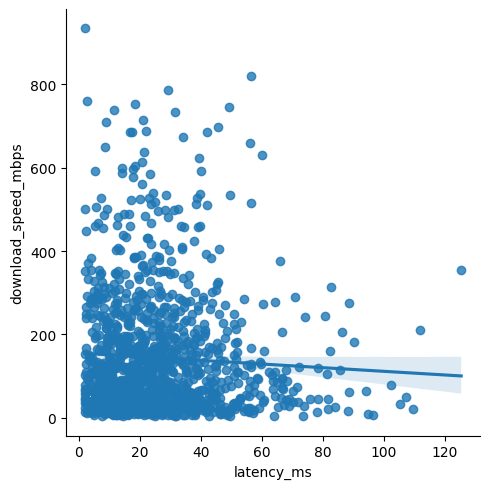

In [89]:
sns.lmplot(data=internet_down_speed,x="latency_ms",y="download_speed_mbps")

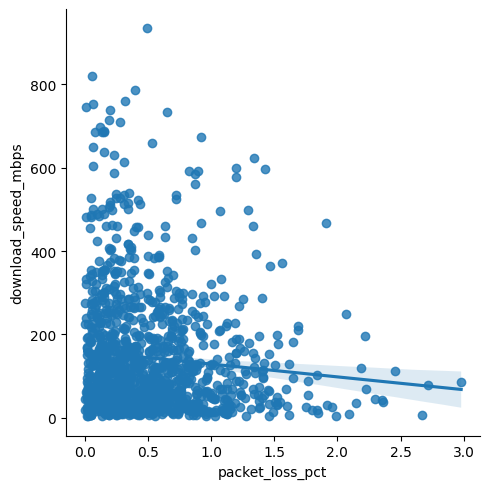

In [28]:
sns.lmplot(data=internet_down_speed,x="packet_loss_pct",y="download_speed_mbps")

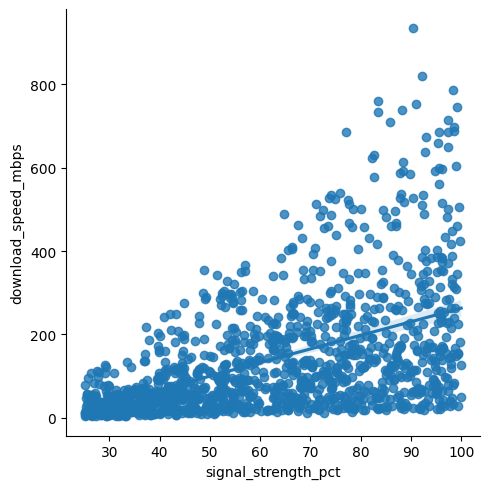

In [26]:
sns.lmplot(data=internet_down_speed,x="signal_strength_pct",y="download_speed_mbps")

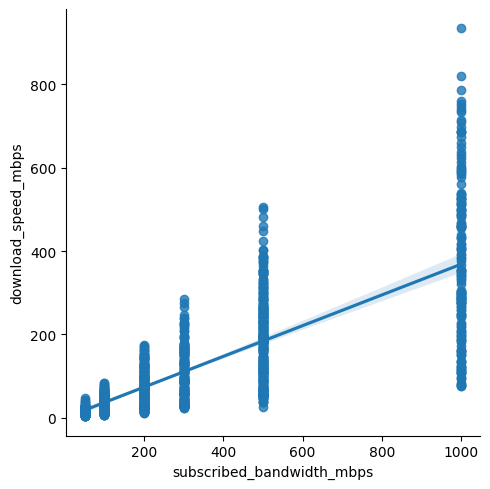

In [30]:
 
sns.lmplot(data=internet_down_speed,x="subscribed_bandwidth_mbps",y="download_speed_mbps")

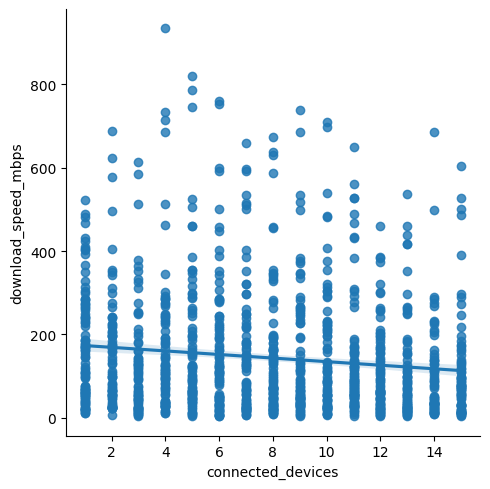

In [31]:
sns.lmplot(data=internet_down_speed,x="connected_devices",y="download_speed_mbps")

In [42]:
internet_down_speed.dtypes

latency_ms                   float64
packet_loss_pct              float64
signal_strength_pct          float64
subscribed_bandwidth_mbps      int64
connected_devices              int64
download_speed_mbps          float64
wifi_band_2.4GHz               int64
wifi_band_5GHz                 int64
time_of_day_Afternoon          int64
time_of_day_Evening            int64
time_of_day_Morning            int64
time_of_day_Night              int64
connection_quality_Good        int64
connection_quality_Poor        int64
dtype: object

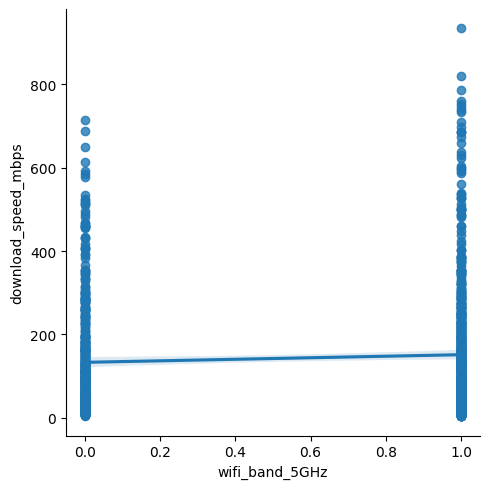

In [49]:
sns.lmplot(data=internet_down_speed,x="wifi_band_5GHz",y="download_speed_mbps")

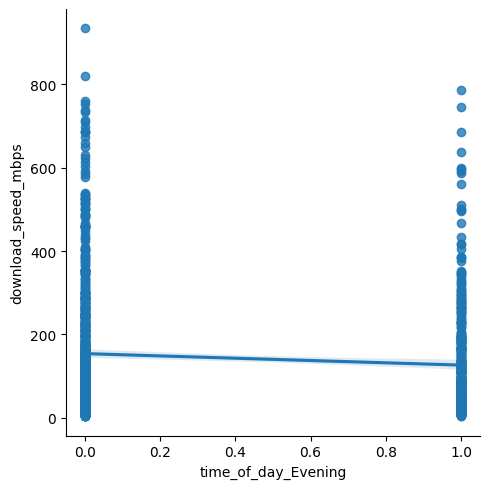

In [52]:
sns.lmplot(data=internet_down_speed,x="time_of_day_Evening",y="download_speed_mbps")

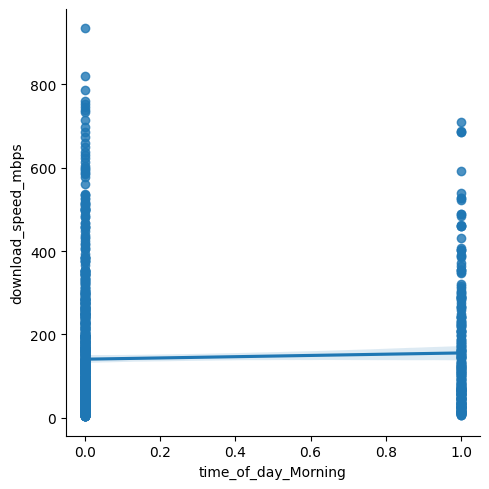

In [54]:
sns.lmplot(data=internet_down_speed,x="time_of_day_Morning",y="download_speed_mbps")

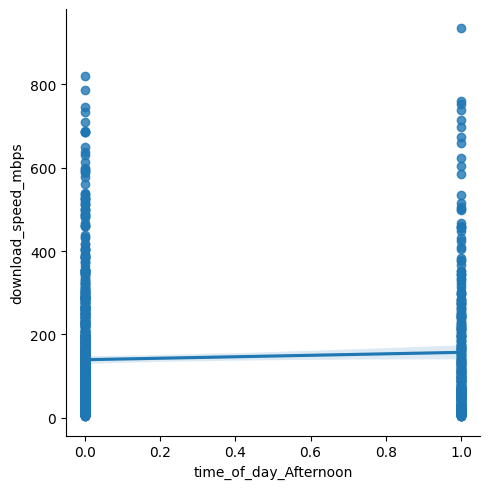

In [50]:
sns.lmplot(data=internet_down_speed,x="time_of_day_Afternoon",y="download_speed_mbps")

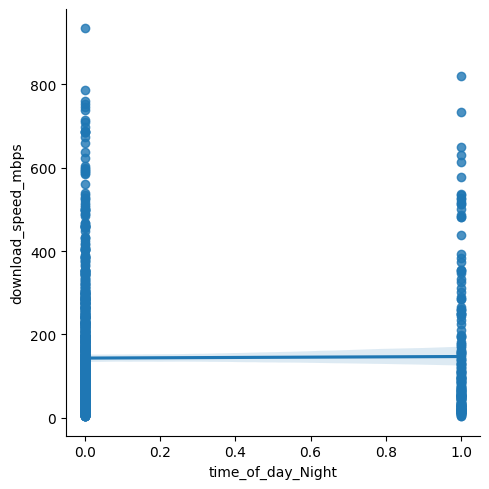

In [55]:
sns.lmplot(data=internet_down_speed,x="time_of_day_Night",y="download_speed_mbps")

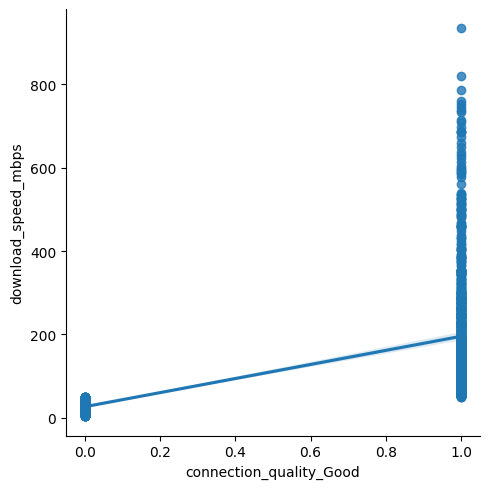

In [48]:
sns.lmplot(data=internet_down_speed,x="connection_quality_Good",y="download_speed_mbps")

<Axes: >

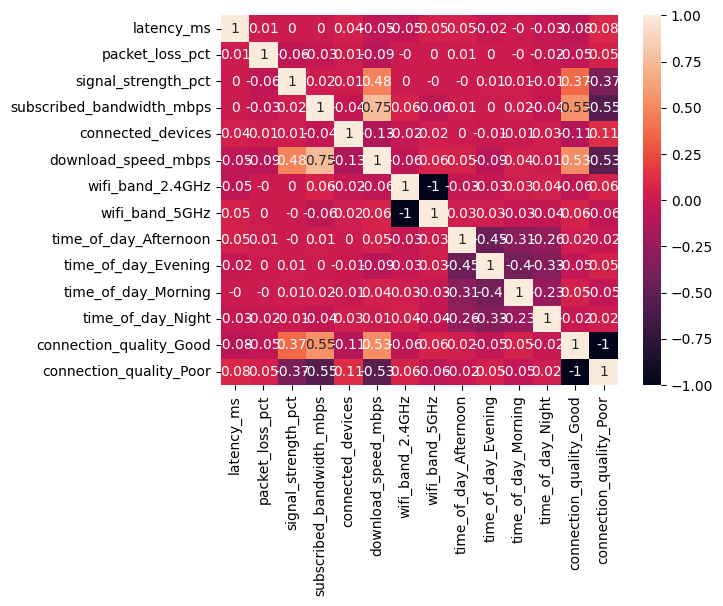

In [66]:
# Test 3 : Correlation matrix :
corr_matrix = internet_down_speed.corr().round(2)
sns.heatmap(corr_matrix,annot=True)

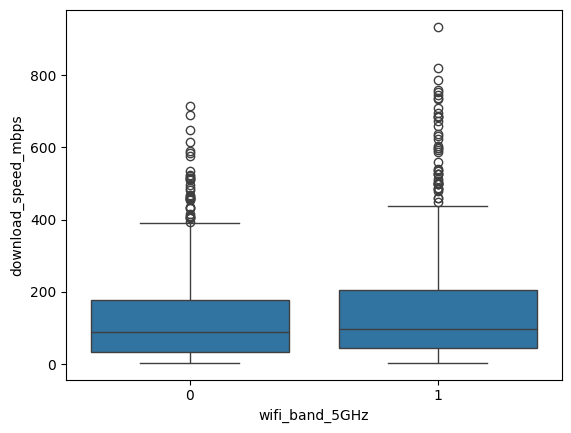

In [62]:
sns.boxplot(
    data=internet_down_speed,
    x='wifi_band_5GHz',
    y='download_speed_mbps'
)
plt.show()

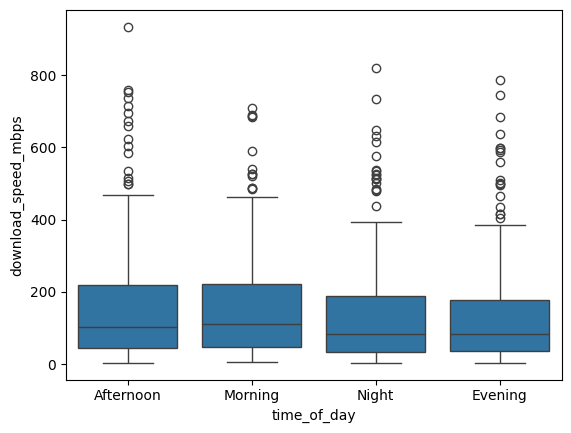

In [64]:
sns.boxplot(
    data=internet_down_speed_original,
    x='time_of_day',
    y='download_speed_mbps'
)

plt.show()

(array([325., 392., 255., 121.,  53.,  29.,  13.,   6.,   5.,   1.]),
 array([  2.   ,  14.339,  26.678,  39.017,  51.356,  63.695,  76.034,
         88.373, 100.712, 113.051, 125.39 ]),
 <BarContainer object of 10 artists>)

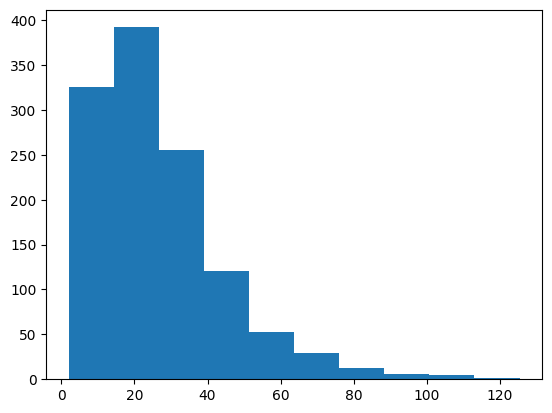

In [75]:
# Test3: Normality test :
plt.hist(x=internet_down_speed["latency_ms"])

(array([461., 339., 210.,  94.,  54.,  21.,   9.,   8.,   2.,   2.]),
 array([0.   , 0.298, 0.596, 0.894, 1.192, 1.49 , 1.788, 2.086, 2.384,
        2.682, 2.98 ]),
 <BarContainer object of 10 artists>)

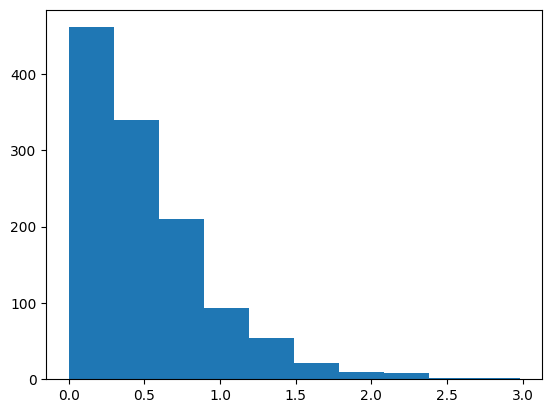

In [68]:
plt.hist(x=internet_down_speed["packet_loss_pct"])

(array([106., 117., 123., 120., 104., 132., 131., 111., 114., 142.]),
 array([ 25.1 ,  32.59,  40.08,  47.57,  55.06,  62.55,  70.04,  77.53,
         85.02,  92.51, 100.  ]),
 <BarContainer object of 10 artists>)

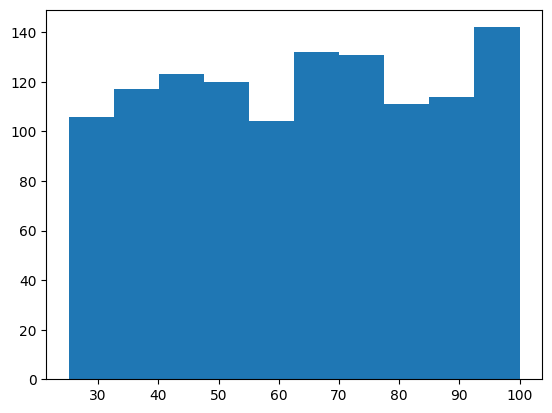

In [69]:
plt.hist(x=internet_down_speed["signal_strength_pct"])

(array([279., 218., 198.,   0., 324.,   0.,   0.,   0.,   0., 181.]),
 array([  50.,  145.,  240.,  335.,  430.,  525.,  620.,  715.,  810.,
         905., 1000.]),
 <BarContainer object of 10 artists>)

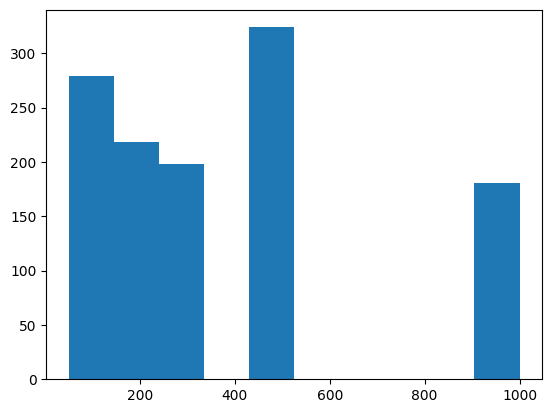

In [70]:
plt.hist(x=internet_down_speed["subscribed_bandwidth_mbps"])

(array([173.,  72., 156.,  87.,  78., 169.,  78., 167.,  76., 144.]),
 array([ 1. ,  2.4,  3.8,  5.2,  6.6,  8. ,  9.4, 10.8, 12.2, 13.6, 15. ]),
 <BarContainer object of 10 artists>)

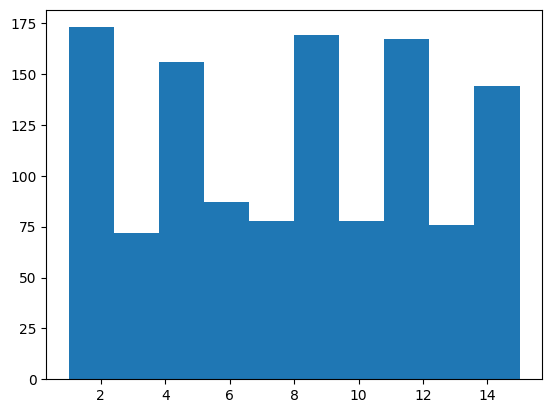

In [71]:
plt.hist(x=internet_down_speed["connected_devices"])

(array([616., 267., 145.,  79.,  35.,  28.,  13.,  12.,   4.,   1.]),
 array([  3.95 ,  96.965, 189.98 , 282.995, 376.01 , 469.025, 562.04 ,
        655.055, 748.07 , 841.085, 934.1  ]),
 <BarContainer object of 10 artists>)

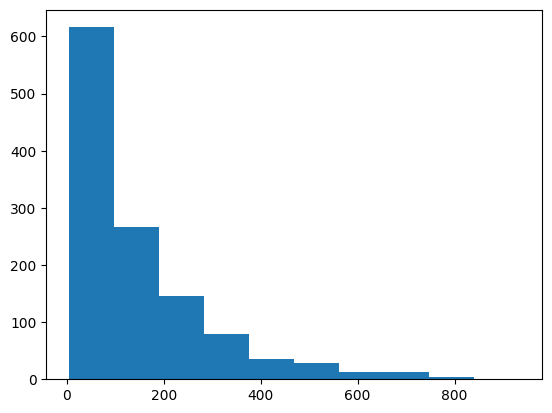

In [72]:
plt.hist(x=internet_down_speed["download_speed_mbps"])

(array([367.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 833.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

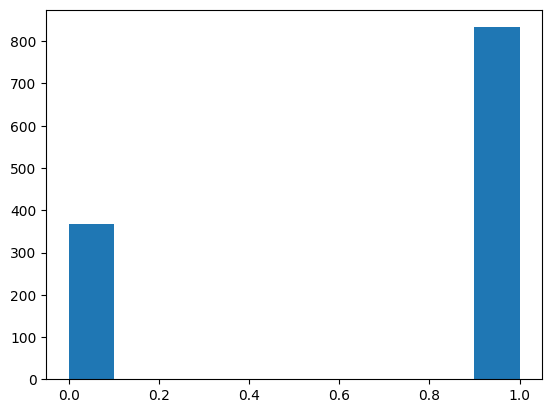

In [74]:
plt.hist(x=internet_down_speed["connection_quality_Good"])

In [76]:
#Test 4: Auto regression : No time based 

In [78]:
#Data preparations :
internet_down_speed

,latency_ms,packet_loss_pct,signal_strength_pct,subscribed_bandwidth_mbps,connected_devices,download_speed_mbps,wifi_band_2.4GHz,wifi_band_5GHz,time_of_day_Afternoon,time_of_day_Evening,time_of_day_Morning,time_of_day_Night,connection_quality_Good,connection_quality_Poor
0,27.78,0.53,39.0,50,8,9.91,0,1,1,0,0,0,0,1
1,37.09,0.11,99.4,200,1,153.91,1,0,0,0,1,0,1,0
2,24.56,0.08,37.1,1000,13,153.38,0,1,0,0,0,1,1,0
3,22.13,0.50,70.0,300,14,139.05,0,1,1,0,0,0,1,0
4,40.13,0.83,94.7,1000,7,592.51,0,1,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,12.27,0.37,95.2,500,7,402.54,0,1,0,0,1,0,1,0
1196,34.10,0.66,70.1,1000,9,336.58,1,0,1,0,0,0,1,0
1197,3.64,0.13,39.7,300,4,81.59,0,1,0,0,1,0,1,0
1198,58.63,0.42,76.0,300,15,95.95,0,1,0,1,0,0,1,0


In [90]:
X = internet_down_speed[["latency_ms","packet_loss_pct","signal_strength_pct","subscribed_bandwidth_mbps","connected_devices","wifi_band_2.4GHz","wifi_band_5GHz","time_of_day_Afternoon","time_of_day_Evening","time_of_day_Morning","time_of_day_Night"]]
Y = internet_down_speed["download_speed_mbps"]

In [92]:
x_train, x_test, y_train, y_test = train_test_split(X,Y,test_size=0.20,
    random_state=34,
    shuffle=True,
    stratify=None,)

In [140]:
# Model training :
from sklearn.linear_model import LinearRegression


In [100]:
linear_model = LinearRegression()
linear_model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [102]:
# Model testing :

linear_model.intercept_

np.float64(-154.5721258661518)

In [103]:
linear_model.coef_

array([ -0.49994233, -12.50697524,   3.21418937,   0.36747238,
        -3.51143532, -16.39867841,  16.39867841,   8.97613681,
       -23.34012707,   4.90018948,   9.46380079])

In [107]:
y_test_predict = linear_model.predict(x_test)

In [108]:
y_train_predict = linear_model.predict(x_train)

In [118]:
error_test = y_test - y_test_predict

In [117]:
error_train = y_train - y_train_predict

In [119]:
error_test

283     -11.237288
1056     85.148973
195      26.300511
1089     47.295521
58      187.678416
           ...    
254     -17.623717
1002     36.139136
1088      0.397336
477      -6.950118
1027     56.143251
Name: download_speed_mbps, Length: 240, dtype: float64

In [120]:
error_train

1062   -158.124992
180     -41.652909
116     -17.691463
970      -2.546659
858       8.498077
           ...    
453    -108.062378
324     -35.286462
1109    -32.343451
490     201.104824
1146     33.419296
Name: download_speed_mbps, Length: 960, dtype: float64

<Axes: ylabel='download_speed_mbps'>

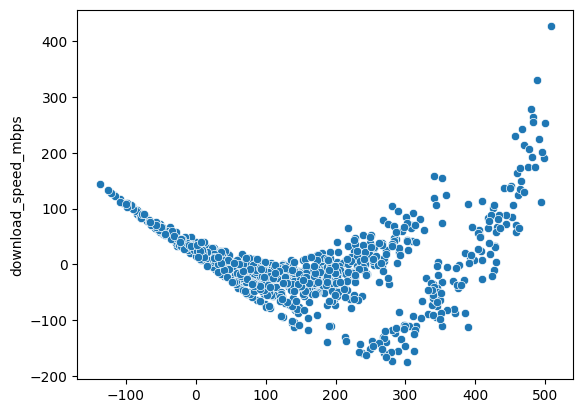

In [141]:
sns.scatterplot(x=y_train_predict, y=error_train)


<Axes: ylabel='download_speed_mbps'>

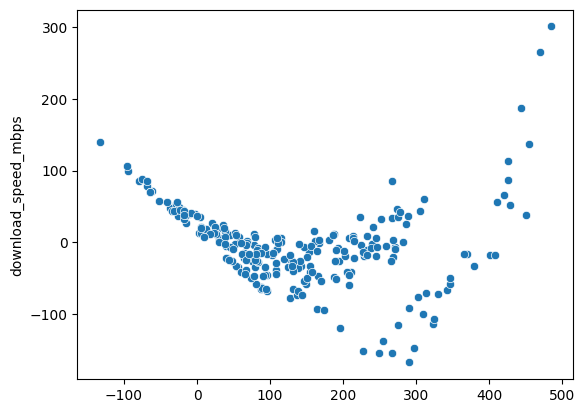

In [142]:
sns.scatterplot(x=y_test_predict, y=error_test)


Text(0, 0.5, 'error_train')

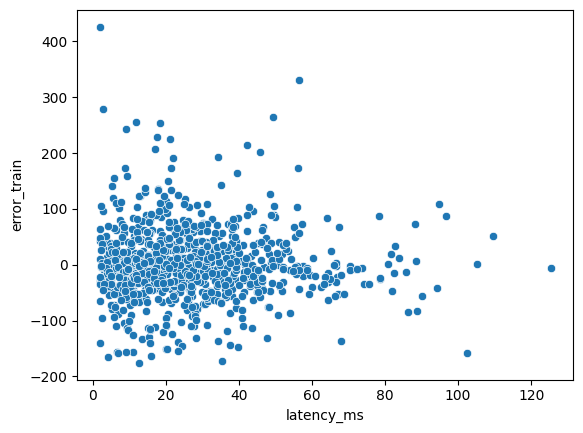

In [162]:
sns.scatterplot(data = internet_down_speed, x=x_train["latency_ms"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

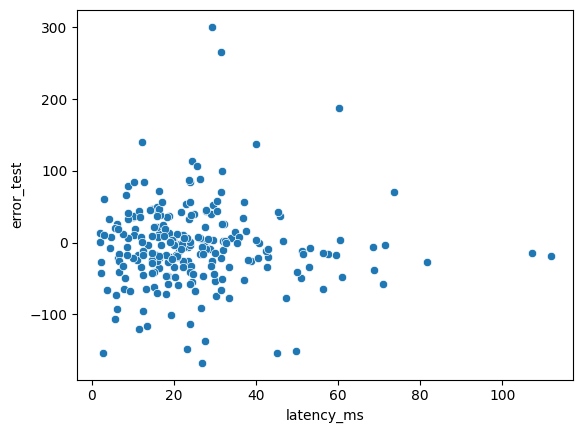

In [163]:
sns.scatterplot(data = internet_down_speed, x=x_test["latency_ms"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'error_train')

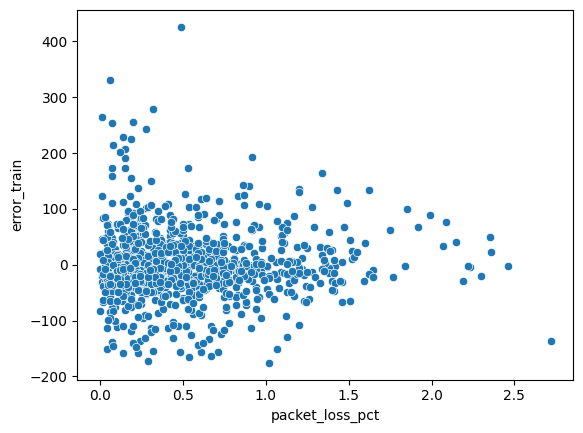

In [164]:
sns.scatterplot(data = internet_down_speed, x=x_train["packet_loss_pct"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

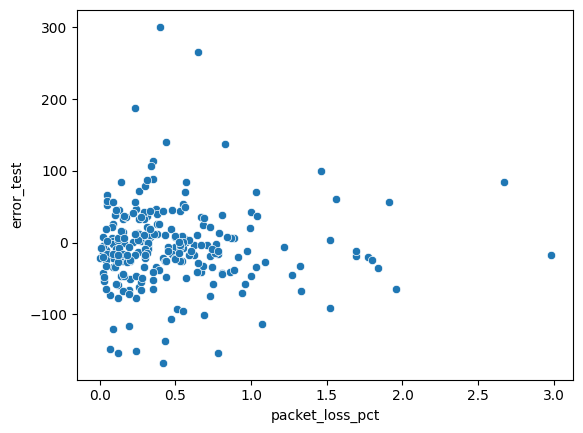

In [165]:
sns.scatterplot(data = internet_down_speed, x=x_test["packet_loss_pct"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'error_train')

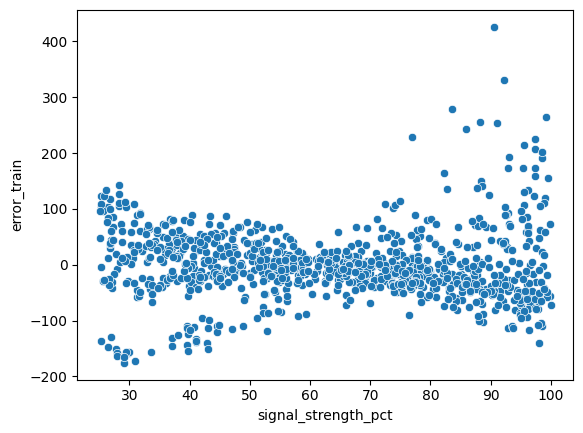

In [171]:
sns.scatterplot(data = internet_down_speed, x= x_train["signal_strength_pct"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

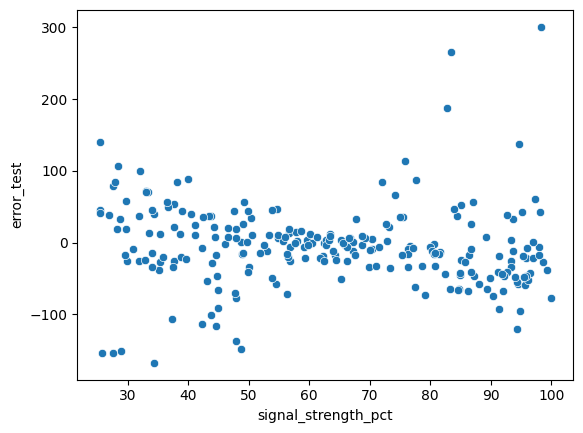

In [166]:
sns.scatterplot(data = internet_down_speed, x=x_test["signal_strength_pct"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'error_train')

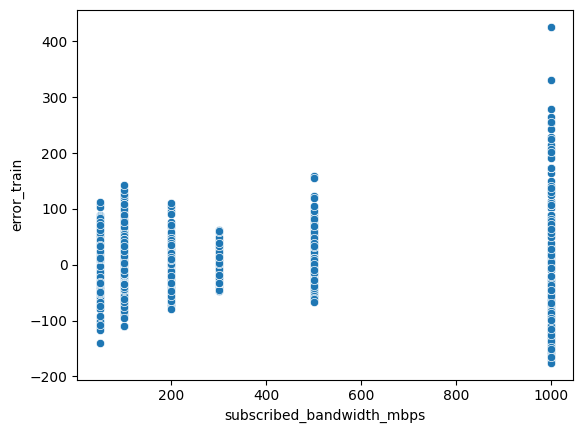

In [172]:
sns.scatterplot(data = internet_down_speed, x=x_train["subscribed_bandwidth_mbps"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

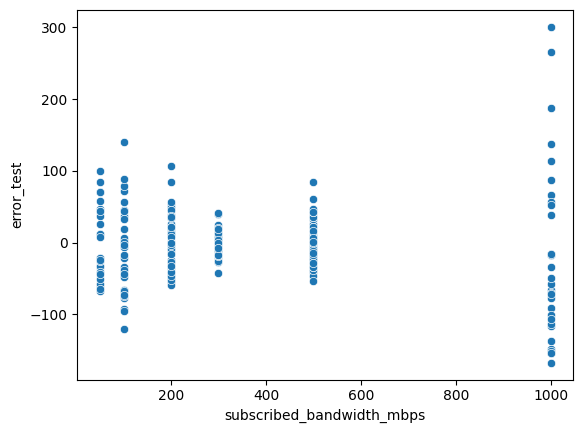

In [167]:
sns.scatterplot(data = internet_down_speed, x=x_test["subscribed_bandwidth_mbps"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'error_train')

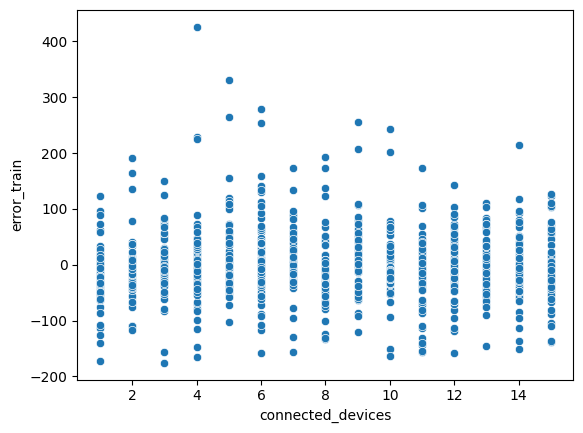

In [173]:
sns.scatterplot(data = internet_down_speed, x=x_train["connected_devices"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

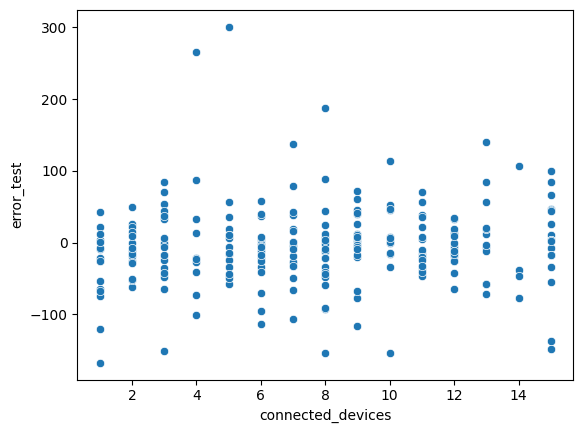

In [168]:
sns.scatterplot(data = internet_down_speed, x=x_test["connected_devices"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'error_train')

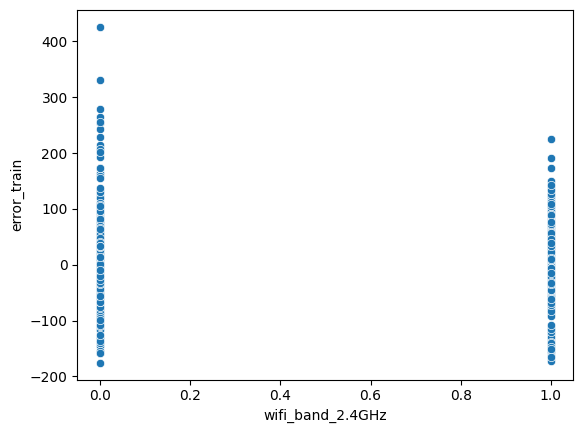

In [174]:
sns.scatterplot(data = internet_down_speed, x=x_train["wifi_band_2.4GHz"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

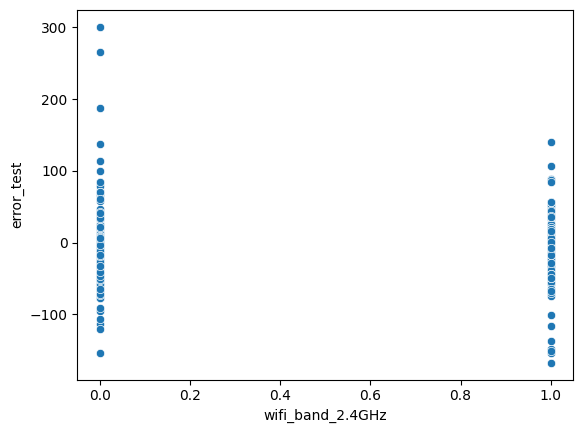

In [169]:
sns.scatterplot(data = internet_down_speed, x=x_test["wifi_band_2.4GHz"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'error_train')

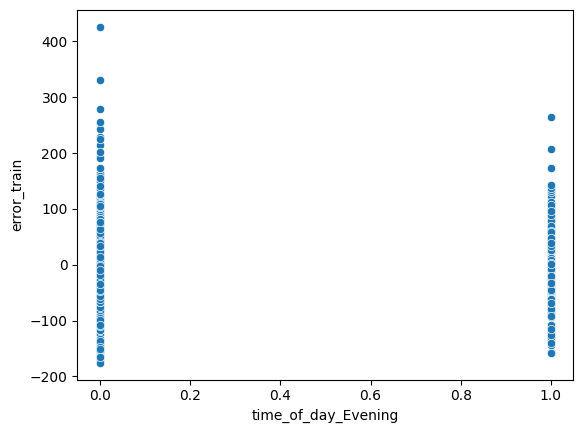

In [175]:

sns.scatterplot(data = internet_down_speed, x=x_train["time_of_day_Evening"], y= error_train)
plt.ylabel("error_train")

Text(0, 0.5, 'error_test')

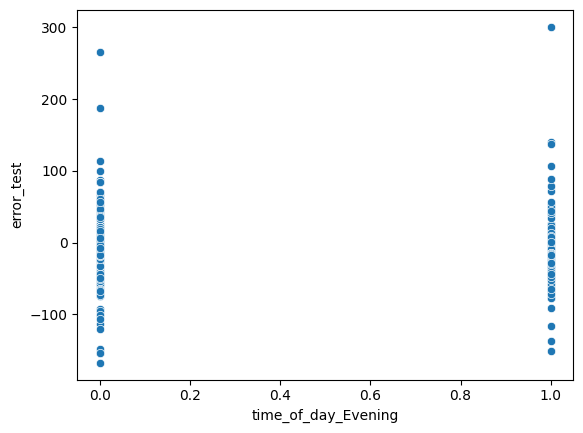

In [170]:
sns.scatterplot(data = internet_down_speed, x=x_test["time_of_day_Evening"], y= error_test)
plt.ylabel("error_test")

Text(0, 0.5, 'predicted o/p')

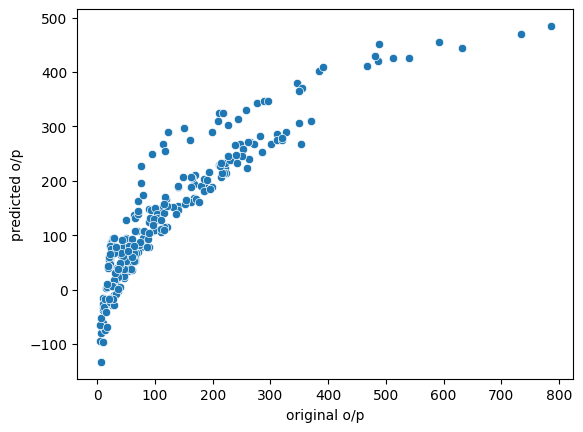

In [179]:

sns.scatterplot(  x=y_test,  y=y_test_predict)
plt.xlabel("original o/p")
plt.ylabel("predicted o/p")

Text(0, 0.5, 'predicted o/p')

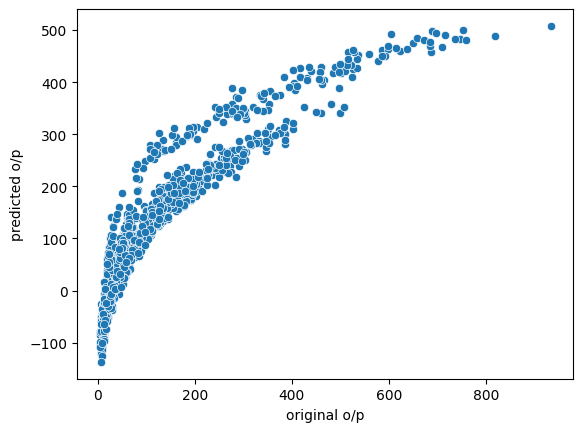

In [180]:

sns.scatterplot(  x=y_train,  y=y_train_predict)
plt.xlabel("original o/p")
plt.ylabel("predicted o/p")

In [181]:
# Evaluation metrics :

In [182]:
error = y_train - y_train_predict

In [194]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [188]:
mean_absolute_error(y_train, y_train_predict)

43.15271718686734

In [189]:
mean_absolute_error(y_test, y_test_predict)

39.81868310290627

In [190]:
mean_squared_error(y_train, y_train_predict)

3865.384492981489

In [191]:
mean_squared_error(y_test, y_test_predict)

3308.2942143968385

In [192]:
root_mean_squared_error(y_test, y_test_predict)

57.517773030575846

In [193]:
root_mean_squared_error(y_train, y_train_predict)

62.17221640718215

In [195]:
r2_score(y_train, y_train_predict)

0.8265238115527201

In [202]:
pip install statsmodels


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



     ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
     --------------------------------------- 0.0/11.4 MB 667.8 kB/s eta 0:00:17
      --------------------------------------- 0.2/11.4 MB 1.7 MB/s eta 0:00:07
     - -------------------------------------- 0.3/11.4 MB 2.6 MB/s eta 0:00:05
     -- ------------------------------------- 0.7/11.4 MB 4.3 MB/s eta 0:00:03
     --- ------------------------------------ 0.9/11.4 MB 4.8 MB/s eta 0:00:03
     ---- ----------------------------------- 1.3/11.4 MB 5.3 MB/s eta 0:00:02
     ------ --------------------------------- 1.7/11.4 MB 5.5 MB/s eta 0:00:02
     ------ --------------------------------- 1.9/11.4 MB 5.2 MB/s eta 0:00:02
     ------- -------------------------------- 2.2/11.4 MB 5.4 MB/s eta 0:00:02
     -------- ------------------------------- 2.5/11.4 MB 5.4 MB/s eta 0:00:02
     --------- ------------------------------ 2.8/11.4 MB 5.5 MB/s eta 0:00:02
     ---------- ----------------------------- 3.0/11.4 MB

In [207]:
import statsmodels.formula.api as smf
linear_model2 = smf.ols(
    formula="""download_speed_mbps ~ latency_ms
    + packet_loss_pct
    + signal_strength_pct
    + subscribed_bandwidth_mbps
    + connected_devices
    + Q("wifi_band_2.4GHz")
    + Q("wifi_band_5GHz")
    + time_of_day_Afternoon
    + time_of_day_Evening
    + time_of_day_Morning
    + time_of_day_Night""",
    data=internet_down_speed
).fit()


C:\Users\gayuu\AppData\Local\Temp\ipykernel_17516\997620072.py:15: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


In [211]:
# Statsmodel R2 squared and R2 adjusted squared
print("R2:", linear_model2.rsquared)
print("Adjusted R2:", linear_model2.rsquared_adj)

R2: 0.825034600202804
Adjusted R2: 0.8237113324732454


In [212]:
# with linear model
print("Training R2:", r2_score(y_train, y_train_predict))
print("Testing R2:", r2_score(y_test, y_test_predict))

Training R2: 0.8265238115527201
Testing R2: 0.8144221359614037
